# B4 — Konvolusi dan Penapisan Spasial (SIMUTEH)
Nama: Try Dymaz Prayoga · NIM 2330511020 · **SEED = 1020**

In [1]:
import sys, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik
def muat(nama, folder="citra"):
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

## Langkah 4.1 Lembar hitung manual (verifikasi dengan kode)

In [2]:
P = np.array([[52, 55, 61, 58], [59, 255, 64, 60], [62, 60, 0, 57], [58, 61, 59, 63]], float)
Q = np.array([[70, 72, 75], [74, 120, 78], [73, 76, 79]], float)
tajam = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float)
G = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
def valid(P, f):
    return np.array([[f(P[y:y+3, x:x+3]) for x in range(2)] for y in range(2)])
print("a) rerata 3x3:\n", valid(P, lambda w: w.mean()).round(2))
print("   Gaussian:\n", valid(P, lambda w: (w * G).sum()).round(2))
print("   median:\n", valid(P, np.median))
for y in range(2):
    for x in range(2):
        print(f"   jendela ({y},{x}) terurut:", sorted(P[y:y+3, x:x+3].ravel().astype(int).tolist()))
v = (Q * tajam).sum()
print(f"b) tajam: 5*120 - (72+74+78+76) = {v:.0f} -> clip = {int(np.clip(v, 0, 255))}")
baris = np.array([12, 30, 45, 70])
for nm, mode in [("zero", "constant"), ("replicate", "edge"), ("reflect_101", "reflect")]:
    p = np.pad(baris, 1, mode=mode)
    print(f"c) {nm:11s}: {p.tolist()} -> rerata 1x3 piksel pertama = ({p[0]}+{p[1]}+{p[2]})/3 = {p[:3].mean():.2f}")

a) rerata 3x3:
 [[74.22 74.44]
 [75.33 75.44]]
   Gaussian:
 [[104.44  77.38]
 [ 77.25  57.44]]
   median:
 [[60. 60.]
 [60. 60.]]
   jendela (0,0) terurut: [0, 52, 55, 59, 60, 61, 62, 64, 255]
   jendela (0,1) terurut: [0, 55, 57, 58, 60, 60, 61, 64, 255]
   jendela (1,0) terurut: [0, 58, 59, 59, 60, 61, 62, 64, 255]
   jendela (1,1) terurut: [0, 57, 59, 60, 60, 61, 63, 64, 255]
b) tajam: 5*120 - (72+74+78+76) = 300 -> clip = 255
c) zero       : [0, 12, 30, 45, 70, 0] -> rerata 1x3 piksel pertama = (0+12+30)/3 = 14.00
c) replicate  : [12, 12, 30, 45, 70, 70] -> rerata 1x3 piksel pertama = (12+12+30)/3 = 18.00
c) reflect_101: [30, 12, 30, 45, 70, 45] -> rerata 1x3 piksel pertama = (30+12+30)/3 = 24.00


## Langkah 4.2 Konvolusi manual vs pustaka (Kode 4.1)

In [3]:
def konvolusi(img, k):            # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):     # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih_bgr, md, mb = muat(nama, "bersih")
bersih = cv2.cvtColor(bersih_bgr, cv2.COLOR_BGR2GRAY)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=1.025 s, filter2D=0.00037 s


asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.021 s, filter2D=0.00024 s


konvolusi_sejati vs filter2D(kernel dibalik): selisih maks = 0


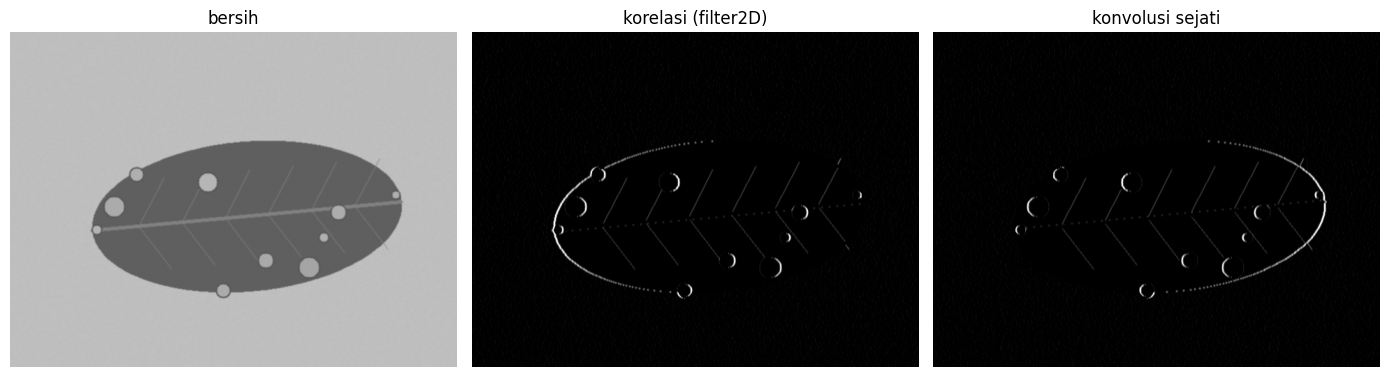

4000x3000: 300,000,000 perkalian
640x480: 7,680,000 perkalian


In [4]:
# Modifikasi: konvolusi sejati via pustaka = filter2D dengan kernel dibalik
k = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
c1 = konvolusi_sejati(bersih, k)
c2 = cv2.filter2D(bersih, -1, cv2.flip(k, -1), borderType=cv2.BORDER_REPLICATE)
print("konvolusi_sejati vs filter2D(kernel dibalik): selisih maks =", np.abs(c1.astype(int) - c2.astype(int)).max())
tampil([bersih, konvolusi(bersih, k), c1], ["bersih", "korelasi (filter2D)", "konvolusi sejati"])
plt.savefig("../hasil/b4_korelasi_konvolusi.png", dpi=110); plt.show()
# P4.6: estimasi jumlah perkalian kernel 5x5
for w, h in [(4000, 3000), (640, 480)]:
    print(f"{w}x{h}: {w*h*25:,} perkalian")

## Langkah 4.3 Tiga penapis, dua jenis derau (Kode 4.2)

In [5]:
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):  # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  4.39
1   gauss_10  rerata_3    36.84      0.05  7.12
2   gauss_10  rerata_5    37.43      0.06  7.25
3   gauss_10   gauss_5    37.64      0.11  7.31
4   gauss_10  median_3    35.48      0.04  7.03
5   gauss_10  median_5    38.33      0.43  8.01
6   gauss_10  median_9    38.17      9.81  8.84
7   gauss_20     tanpa    22.11      0.00  2.46
8   gauss_20  rerata_3    31.41      0.05  5.57
9   gauss_20  rerata_5    34.40      0.07  6.53
10  gauss_20   gauss_5    32.55      0.09  5.97
11  gauss_20  median_3    29.73      0.14  5.03
12  gauss_20  median_5    33.43      0.46  6.47
13  gauss_20  median_9    35.23      9.82  7.24
14  gauss_40     tanpa    16.40      0.00  1.29
15  gauss_40  rerata_3    25.85      0.05  3.54
16  gauss_40  rerata_5    29.75      0.07  4.94
17  gauss_40   gauss_5    27.07      0.07  3.96
18  gauss_40  median_3    23.82      0.05  3.00
19  gauss_40  median_5    27.81      0.3

         Gaussian 20                Garam-merica 4%               
             PSNR_dB waktu_ms    KB         PSNR_dB waktu_ms    KB
penapis                                                           
tanpa          22.11     0.00  2.46           19.26     0.00  1.87
rerata_3       31.41     0.05  5.57           28.42     0.05  4.68
rerata_5       34.40     0.07  6.53           31.69     0.06  6.00
gauss_5        32.55     0.09  5.97           29.55     0.04  5.17
median_3       29.73     0.14  5.03           47.96     0.05  8.46
median_5       33.43     0.46  6.47           44.63     0.36  8.59
median_9       35.23     9.82  7.24           40.33    11.88  9.09


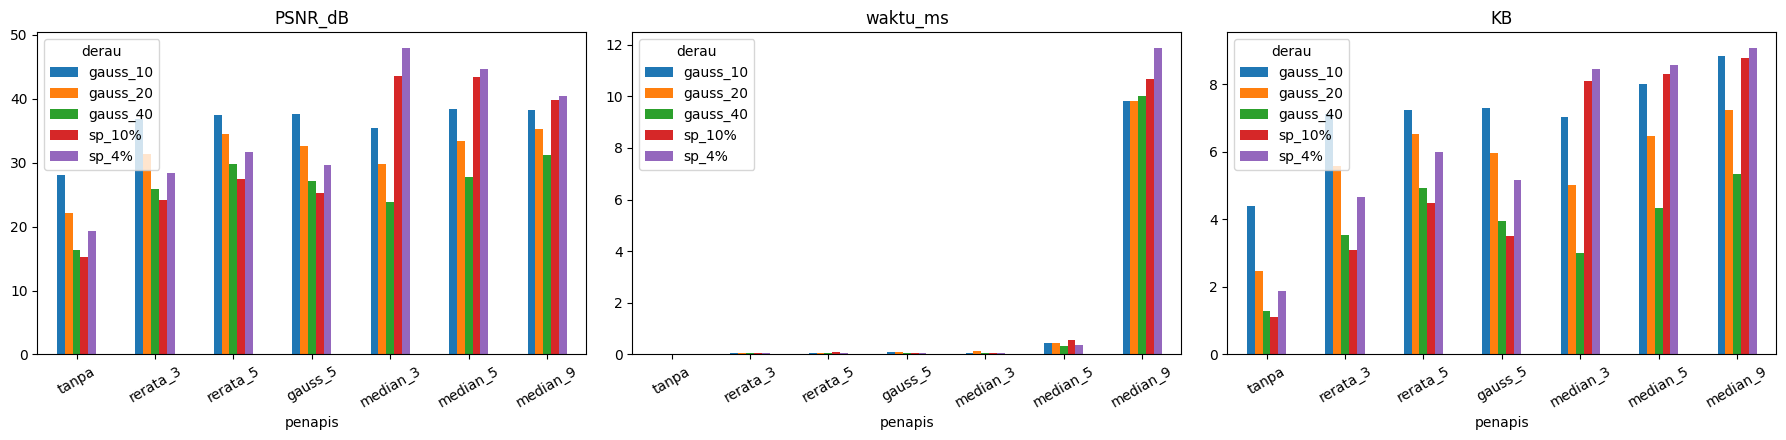

In [6]:
# Tabel 11 (Gaussian 20 dan garam-merica 4%) dan grafik seluruh hasil
g20 = tabel[tabel.derau == "gauss_20"].set_index("penapis")[["PSNR_dB", "waktu_ms", "KB"]]
sp4 = tabel[tabel.derau == "sp_4%"].set_index("penapis")[["PSNR_dB", "waktu_ms", "KB"]]
tabel11 = pd.concat({"Gaussian 20": g20, "Garam-merica 4%": sp4}, axis=1)
print(tabel11); tabel11.to_csv("../hasil/b4_tabel11.csv")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for col, a in zip(["PSNR_dB", "waktu_ms", "KB"], ax):
    tabel.pivot(index="penapis", columns="derau", values=col).loc[["tanpa"] + list(penapis)].plot.bar(ax=a)
    a.set_title(col); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_penapis.png", dpi=110); plt.show()

## Langkah 4.4 Bercak kecil vs ukuran kernel median (Kode 4.3)

           dI    KB
kernel             
1       28.07  4.41
3       28.36  4.53
5       27.07  4.38
9       19.09  3.52
15       4.50  1.16


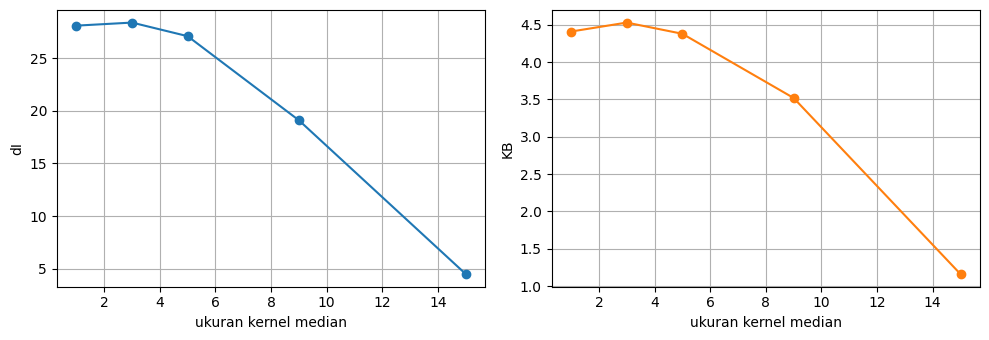

In [7]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:  # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
ring = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(ring); ring.to_csv("../hasil/b4_median_ringan.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ring.index, ring.dI, "o-"); ax[0].set_xlabel("ukuran kernel median"); ax[0].set_ylabel("dI"); ax[0].grid(True)
ax[1].plot(ring.index, ring.KB, "o-", color="tab:orange"); ax[1].set_xlabel("ukuran kernel median"); ax[1].set_ylabel("KB"); ax[1].grid(True)
plt.tight_layout(); plt.savefig("../hasil/b4_dI_kernel.png", dpi=110); plt.show()

bercak terkecil: luas 149 px di (235,92)


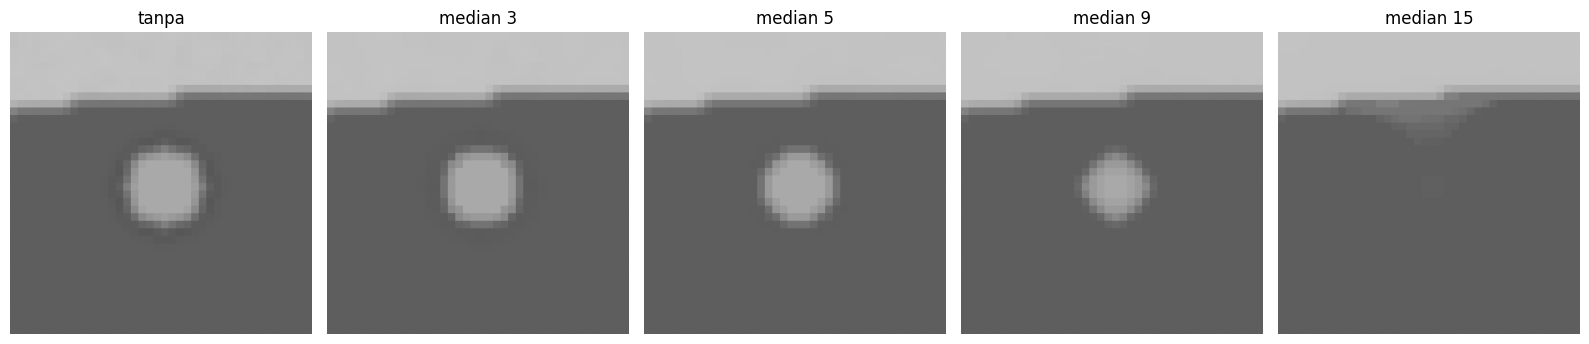

In [8]:
# Potongan satu bercak kecil yang diperbesar (bercak terkecil pada teh_021)
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
n, lab, st, cen = cv2.connectedComponentsWithStats(mb2)
i = 1 + int(np.argmin(st[1:, cv2.CC_STAT_AREA]))
cx, cy = map(int, cen[i]); r = 20
y0, x0 = max(cy - r, 0), max(cx - r, 0)
print(f"bercak terkecil: luas {st[i, cv2.CC_STAT_AREA]} px di ({cx},{cy})")
pot = [g if k == 1 else cv2.medianBlur(g, k) for k in [1, 3, 5, 9, 15]]
pot = [cv2.resize(p[y0:y0+2*r, x0:x0+2*r], None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST) for p in pot]
tampil(pot, ["tanpa", "median 3", "median 5", "median 9", "median 15"], ukuran=(16, 3.6))
plt.savefig("../hasil/b4_crop_bercak.png", dpi=110); plt.show()

## Langkah 4.5 Urutan meredam derau dan menajamkan (Kode 4.4)

In [9]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0  # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))  # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))  # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.35 sigma_latar=8.1 | redam->tajam PSNR=30.19 sigma_latar=8.3
Median: tajam->redam PSNR=30.14 sigma_latar=8.2 | redam->tajam PSNR=31.10 sigma_latar=7.3


## Langkah 4.6 Penapis pada derau sensor bawaan, 12 citra kondisi normal (kerjakan sendiri)
Penapis pilihan: **Gaussian 5x5, sigma 1,0** (derau sensor bawaan bersifat Gaussian; berdasarkan Kode 4.2 penapis ini memberi PSNR tinggi dengan waktu kecil dan tidak terlalu mengikis bercak kecil). Median 3 ditampilkan sebagai pembanding.

In [10]:
baris46 = []
for i in range(1, 61, 5):  # teh_001, teh_006, ..., teh_056
    nm = f"teh_{i:03d}.png"
    d = label.set_index("nama_file").loc[nm]
    assert d.kondisi_cahaya == "normal"
    noisy = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    ref = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    baris46.append([nm, d.kelas, cv2.PSNR(ref, noisy),
                    cv2.PSNR(ref, cv2.GaussianBlur(noisy, (5, 5), 1.0)),
                    cv2.PSNR(ref, cv2.medianBlur(noisy, 3))])
t46 = pd.DataFrame(baris46, columns=["citra", "kelas", "PSNR_sebelum", "PSNR_gauss5", "PSNR_median3"]).round(2)
t46.loc["rerata"] = ["rerata", "", *t46[["PSNR_sebelum", "PSNR_gauss5", "PSNR_median3"]].mean().round(2)]
print(t46.to_string(index=False)); t46.to_csv("../hasil/b4_psnr_normal.csv", index=False)

      citra  kelas  PSNR_sebelum  PSNR_gauss5  PSNR_median3
teh_001.png  sehat         33.69        41.84         40.71
teh_006.png  sehat         31.05        40.19         38.34
teh_011.png  sehat         35.47        42.99         42.21
teh_016.png  sehat         32.42        40.96         39.52
teh_021.png ringan         34.23        41.98         41.16
teh_026.png ringan         30.84        40.14         38.13
teh_031.png ringan         33.09        41.58         40.12
teh_036.png ringan         32.36        41.07         39.53
teh_041.png  berat         28.69        38.07         36.04
teh_046.png  berat         29.01        38.28         36.33
teh_051.png  berat         32.80        40.55         39.76
teh_056.png  berat         30.20        39.02         37.48
     rerata                31.99        40.56         39.11
